# Proyecto Omicron: Predicción de Demanda de Taxis

## Descripción del proyecto

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en aeropuertos. El objetivo de este proyecto es desarrollar un modelo de aprendizaje automático capaz de predecir la cantidad de pedidos de taxis para la próxima hora.

Una predicción precisa permitirá anticipar períodos de alta demanda y atraer un número adecuado de conductores, mejorando así la disponibilidad del servicio y reduciendo los tiempos de espera de los clientes.

## Objetivo

Construir un modelo de regresión para series temporales que prediga el número de pedidos de taxis durante la siguiente hora.

## Criterio de éxito

La métrica de evaluación será la Raíz del Error Cuadrático Medio (RECM o RMSE). Para que el proyecto sea considerado exitoso, el modelo final deberá alcanzar:

**RECM < 48** en el conjunto de prueba.

## Etapas del proyecto

1. Cargar y preparar los datos.
2. Remuestrear la información en intervalos de una hora.
3. Realizar un análisis exploratorio de la serie temporal.
4. Crear características basadas en el tiempo, desfases (lags) y medias móviles.
5. Entrenar diferentes modelos con diversos hiperparámetros.
6. Evaluar el desempeño utilizando RECM.
7. Comparar resultados y seleccionar el mejor modelo.
8. Elaborar conclusiones y recomendaciones finales.

## Herramientas

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-Learn
- LightGBM (opcional)
- XGBoost (opcional)

## Objetivo de negocio

Desarrollar una solución predictiva que permita estimar la demanda de taxis con una hora de anticipación para apoyar la planificación operativa de conductores y mejorar la eficiencia del servicio.

Primero importamos nuestro dataset a nuestro entorno de trabajo

In [1]:
import pandas as pd

taxi = pd.read_csv("/content/taxi.csv")

Ahora analizamos de forma general nuestro dataset

In [2]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26496 entries, 0 to 26495
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   datetime    26496 non-null  object
 1   num_orders  26496 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 414.1+ KB


Podemos apreciar que nuestro dataset contiene 2 columnas junto con 26.496 observaciones, no distinguimos valores faltantes hasta el momento.

Sin embargo desde ya podemos apreciar que los datos de la columna datetime están indexados en forma object. Lo ideal será convertirlos al formato datetime64[ns] más adelante.

In [3]:
taxi.isna().sum()

,0
datetime,0
num_orders,0


Podemos confirmar que nuestro dataset no contiene valores faltantes

In [4]:
taxi.head()

,datetime,num_orders
0,2018-03-01 00:00:00,9
1,2018-03-01 00:10:00,14
2,2018-03-01 00:20:00,28
3,2018-03-01 00:30:00,20
4,2018-03-01 00:40:00,32


Procedemos a analizar el contenido de nuestro dataset. Podemos ver que fuera de la columna que guarda nuestras fechas tenemos valores que nos indican el número de orden.

Dado que este número de orden no representa un valor medible, consideramos que esta columna no debería mostrar valores anormales que podamos clasificar como amormalmente altos o bajos.

Sin embargo procederemos a analizar rápidamente mediante de forma estadística y graficada el comporatamiento de esta columna más adelante.

In [5]:
taxi["datetime"] = pd.to_datetime(taxi["datetime"])

Convertimos nuestra columna datetime (antes de tipo object) a valores de tipo datetime64[ns] y confirmamos dicha conversión.

In [6]:
taxi["datetime"].dtypes

dtype('<M8[ns]')

Ordenamos nuestro dataset de forma ascendente y verificamos dicho reordenamiento.

In [7]:
taxi_ordenado = taxi.sort_values(by = "datetime")

In [8]:
taxi_ordenado.head(5)

,datetime,num_orders
0,2018-03-01 00:00:00,9
1,2018-03-01 00:10:00,14
2,2018-03-01 00:20:00,28
3,2018-03-01 00:30:00,20
4,2018-03-01 00:40:00,32


In [9]:
taxi_ordenado.describe()

,datetime,num_orders
count,26496,26496.000000
mean,2018-05-31 23:55:00,14.070463
min,2018-03-01 00:00:00,0.000000
25%,2018-04-15 23:57:30,8.000000
50%,2018-05-31 23:55:00,13.000000
75%,2018-07-16 23:52:30,19.000000
max,2018-08-31 23:50:00,119.000000
std,NaN,9.211330


In [10]:
filtro = taxi_ordenado[taxi_ordenado["num_orders"] == 0]
print(filtro)

                 datetime  num_orders
32    2018-03-01 05:20:00           0
34    2018-03-01 05:40:00           0
35    2018-03-01 05:50:00           0
36    2018-03-01 06:00:00           0
37    2018-03-01 06:10:00           0
...                   ...         ...
25379 2018-08-24 05:50:00           0
25666 2018-08-26 05:40:00           0
26106 2018-08-29 07:00:00           0
26245 2018-08-30 06:10:00           0
26246 2018-08-30 06:20:00           0

[537 rows x 2 columns]


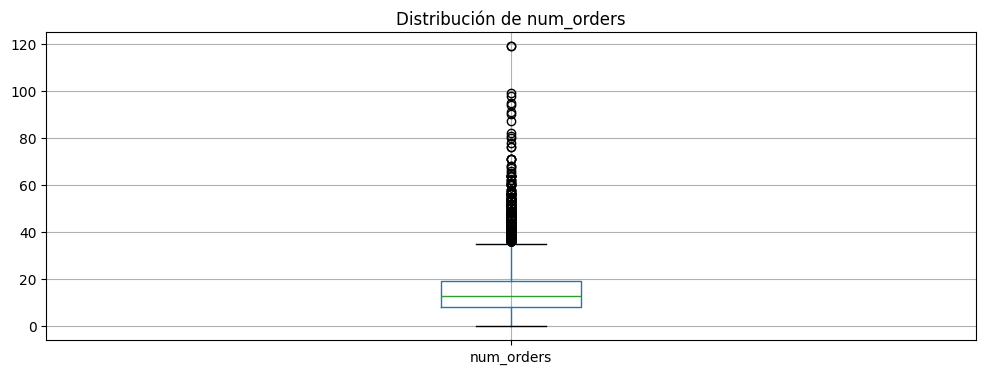

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 4))
taxi_ordenado.boxplot(column = "num_orders")
plt.title("Distribución de num_orders")
plt.show()

Mediante la graficación de caja de bigotes y los resultados estadídticos podemos ver que valores máximos o mínimos el cual está registrado en 0 no representa un problema de lógica en nuestro dataset, ya que, como habíamos mencionado anteriormente estos valores numéricos de la columna (num_orders) representa un valor numérico respecto a la cantidad de taxis pedidos una determinada fecha. mínimos, máximos y "anómalos" no escapan de la lógica de negocio.

Con el fin de cumplir con los requisitos de nuestro proyecto remuestreamos nuestros datos en lapsos de una hora. Para esto reorganizamos nuestro dataset de modo que la cantidad de pedidos de taxis están indexados bajo los valores de las fechas, más exactamente bajo las horas.

In [12]:
taxi_orden = taxi_ordenado.set_index("datetime")

In [13]:
taxi_orden.index

DatetimeIndex(['2018-03-01 00:00:00', '2018-03-01 00:10:00',
               '2018-03-01 00:20:00', '2018-03-01 00:30:00',
               '2018-03-01 00:40:00', '2018-03-01 00:50:00',
               '2018-03-01 01:00:00', '2018-03-01 01:10:00',
               '2018-03-01 01:20:00', '2018-03-01 01:30:00',
               ...
               '2018-08-31 22:20:00', '2018-08-31 22:30:00',
               '2018-08-31 22:40:00', '2018-08-31 22:50:00',
               '2018-08-31 23:00:00', '2018-08-31 23:10:00',
               '2018-08-31 23:20:00', '2018-08-31 23:30:00',
               '2018-08-31 23:40:00', '2018-08-31 23:50:00'],
              dtype='datetime64[ns]', name='datetime', length=26496, freq=None)

Ahora procedemos a remuestrear los datos para que caigan en valores de una hora.

In [14]:
taxi_orden_1 = taxi_orden.resample("1h").sum()

In [15]:
taxi_orden_1.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


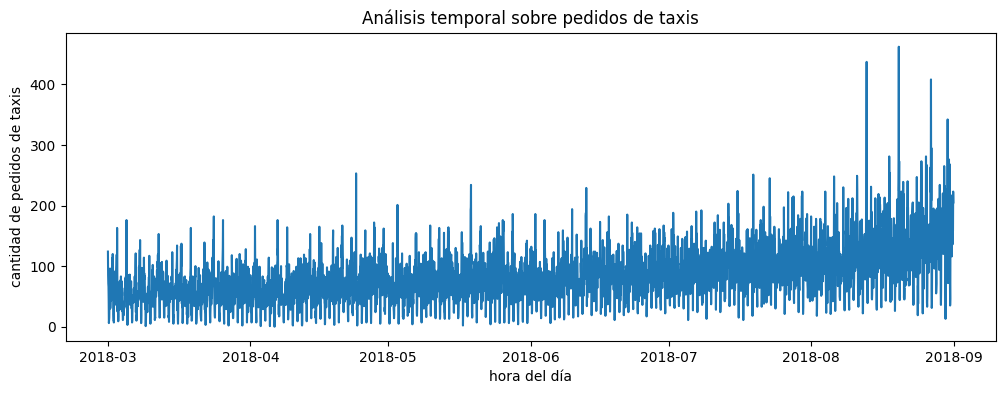

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 4))
plt.plot(taxi_orden_1)
plt.title("Análisis temporal sobre pedidos de taxis")
plt.ylabel("cantidad de pedidos de taxis")
plt.xlabel("hora del día")
plt.show()

Mediante este análisis podemos observar resultados interesantes.

El comportamiento de los pedidos a lo largo de los meses podría sugerirnos comportamientos  de tendencia, ya que en los primeros meses suele presentarse una cantidad de pedidos moderados, algo que no vemos para el mes final que presenta pedidos aproximadamente entre25 y más de 400 taxis.

También podemos observar que existen más fluctuaciones a lo largo del tiempo, podría existir más variabilidad.

En este momento vamos a confirmar si existe o no un comportamiento de tendencia en nuestros datos

In [17]:
from statsmodels.tsa.seasonal import seasonal_decompose

descomposicion = seasonal_decompose(taxi_orden_1, period = 24)

<Figure size 2500x2600 with 0 Axes>

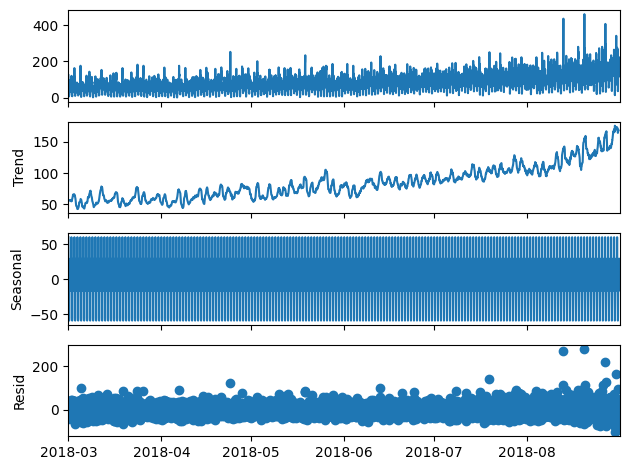

In [18]:
plt.figure(figsize = (25, 26))
descomposicion.plot()
plt.show()

Mediante la información vista podemos confirmar que las tendencias sobre el aumento del pedido de taxis es real y efectivamente aumentan para los meses de julio-agosto.

Además podemos ver que también existe estacionalidad en periodos de 24 horas, vemos que son patrones fuertes y repetitivos que muestran horas donde el pedido de taxis puede llegar a ser muy bajo.

El componente residual representa la variación de la demanda que no puede ser explicada por la tendencia ni por la estacionalidad. Se observa que los residuos se distribuyen alrededor de cero, lo que sugiere que ambos componentes logran capturar una parte importante del comportamiento de la serie temporal. Sin embargo, también se aprecian algunos valores extremos, especialmente hacia el final del período analizado, lo que indica la presencia de eventos o fluctuaciones inesperadas en la demanda de taxis.

Si analizamos nuestro dataset podemos observar que tenemos una sola característica (num_orders). Por lo que se presenta la necesidad de extraer distintos espacios de tiempo de forma independiente de forma que nuestros próximos modelos tengan más características con las cuales puedan aprender de patrones significativos e importantes.

Esto además de que nos permite establecer nuestra predicción al rango temporal que consideremos necesario (hora, día, día de la semana, mes y año).

In [19]:
taxi_orden_1.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


In [20]:
taxi_orden_1["Hora"] = taxi_orden_1.index.hour
taxi_orden_1["Mes"] = taxi_orden_1.index.month
taxi_orden_1["Día"] = taxi_orden_1.index.day
taxi_orden_1["Día de la semana"] = taxi_orden_1.index.dayofweek
taxi_orden_1["Año"] = taxi_orden_1.index.year

In [21]:
taxi_orden_1.head()

,num_orders,Hora,Mes,Día,Día de la semana,Año
datetime,,,,,,
2018-03-01 00:00:00,124,0,3,1,3,2018
2018-03-01 01:00:00,85,1,3,1,3,2018
2018-03-01 02:00:00,71,2,3,1,3,2018
2018-03-01 03:00:00,66,3,3,1,3,2018
2018-03-01 04:00:00,43,4,3,1,3,2018


Ahora analizaremos la cantidad promedio de pedidos de taxis en cada hora del día

In [22]:
taxi_orden_1.groupby("Hora")["num_orders"].mean()

,num_orders
Hora,
0,144.402174
1,104.364130
2,113.070652
3,102.021739
4,86.907609
5,42.630435
6,25.173913
7,29.271739
8,73.048913


Con esta información en consideración podemos observar que se presentan horas especiales donde la demanda de taxis aumenta considerablemente, especialmente sobre el espacio de 14:00 a las 16:00 horas (de 2 a 4 de la tarde).

Podemos concluir además que no hay hora con cantidades alarmantemente bajas, dado que el espacio del día con menos actividad se registra con una cantidad de un promedio de 29 taxis para las 7:00 am.

Procedemos a realizar un lag de una hora y sobre 24 horas antes con el fin de que nuestros modelos puedan predecir más adelante sobre una hora futura.

Ambos datos (una hora antes y 24 horas antes) ayudarán al modelo a encontrar patrones más importantes, dado que la hora proporciona un dato inmediatamente anterior a la hora que queremos predecir y 24 horas antes ya que al presentarse como una estacionalidad también puede guardar patrones de interes los cuales puedan "repetirse" en el futuro.

Entendemos que el lag será sobre el tiempo de una hora ya que sobre ese valor remuestreamos anteriormente.

In [23]:
taxi_orden_1["Lag_1"] = taxi_orden_1["num_orders"].shift(1)
taxi_orden_1["lag_24"] = taxi_orden_1["num_orders"].shift(24)

taxi_orden_1.head(30)

,num_orders,Hora,Mes,Día,Día de la semana,Año,Lag_1,lag_24
datetime,,,,,,,,
2018-03-01 00:00:00,124,0,3,1,3,2018,NaN,NaN
2018-03-01 01:00:00,85,1,3,1,3,2018,124.0,NaN
2018-03-01 02:00:00,71,2,3,1,3,2018,85.0,NaN
2018-03-01 03:00:00,66,3,3,1,3,2018,71.0,NaN
2018-03-01 04:00:00,43,4,3,1,3,2018,66.0,NaN
2018-03-01 05:00:00,6,5,3,1,3,2018,43.0,NaN
2018-03-01 06:00:00,12,6,3,1,3,2018,6.0,NaN
2018-03-01 07:00:00,15,7,3,1,3,2018,12.0,NaN
2018-03-01 08:00:00,34,8,3,1,3,2018,15.0,NaN


Procedemos a encontrar los valores medios en una ventana de 24 horas para conocer los valores más comunes que se presentan como pedidos de taxis. Estos datos nos proporcionan los pedidos medios que con más frecuencia se reportaron.

In [24]:
taxi_orden_1["media_rodante"] = taxi_orden_1["num_orders"].shift(1).rolling(24).mean()
taxi_orden_1.head(40)

,num_orders,Hora,Mes,Día,Día de la semana,Año,Lag_1,lag_24,media_rodante
datetime,,,,,,,,,
2018-03-01 00:00:00,124,0,3,1,3,2018,NaN,NaN,NaN
2018-03-01 01:00:00,85,1,3,1,3,2018,124.0,NaN,NaN
2018-03-01 02:00:00,71,2,3,1,3,2018,85.0,NaN,NaN
2018-03-01 03:00:00,66,3,3,1,3,2018,71.0,NaN,NaN
2018-03-01 04:00:00,43,4,3,1,3,2018,66.0,NaN,NaN
2018-03-01 05:00:00,6,5,3,1,3,2018,43.0,NaN,NaN
2018-03-01 06:00:00,12,6,3,1,3,2018,6.0,NaN,NaN
2018-03-01 07:00:00,15,7,3,1,3,2018,12.0,NaN,NaN
2018-03-01 08:00:00,34,8,3,1,3,2018,15.0,NaN,NaN


Debido al uso de lags y medias movibles es normal que se generen valores faltantes NaN, estos datos faltantes podemos decir que contaminarían nuestro posterior modelado, por lo que procederemos a eliminarlas.

In [25]:
taxi_orden_1.isna().sum()

,0
num_orders,0
Hora,0
Mes,0
Día,0
Día de la semana,0
Año,0
Lag_1,1
lag_24,24
media_rodante,24


In [26]:
taxi_orden_1 = taxi_orden_1.dropna()

In [27]:
taxi_orden_1.isna().sum()

,0
num_orders,0
Hora,0
Mes,0
Día,0
Día de la semana,0
Año,0
Lag_1,0
lag_24,0
media_rodante,0


Separamos nuestro dataset en caracteristicas y objetivo usando las columnas enriquecidas anteriormente

In [28]:
objetivo = taxi_orden_1["num_orders"]

caracteristicas = taxi_orden_1.drop(["num_orders"], axis = 1)

Verificamos las dimensiones de nuestra separación de datos

In [29]:
print(objetivo.shape)
print(caracteristicas.shape)

(4392,)
(4392, 8)


Preparamos nuestros conjuntos de entrenamiento y prueba asegurandonos de no mezclar las observaciones dado que al tratarse de una predicción basada en series temporales, nuestros conjuntos de datos siguen una linealidad específica.

In [30]:
from sklearn.model_selection import train_test_split

caracteristicas_entrenamiento, caracteristicas_prueba, objetivo_entrenamiento, objetivo_prueba = train_test_split(caracteristicas, objetivo, test_size = 0.10, shuffle = False)

Tomando en cuenta que nuestro proyecto tiene como requisito obtener un RECM inferior a 48 no consideramos estrictamente innecesario construír un modelo base contra el cual comparar nuestros resultados. Aunque igualmente se procede a generar dicho modelo base, manteniendo las buenas prácticas en machine learning.

In [31]:
%%time

from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

modelo_base =  DummyRegressor(strategy = "mean")

modelo_base.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_base = modelo_base.predict(caracteristicas_prueba)

RECM_base = root_mean_squared_error(objetivo_prueba, prediccion_base)

print("La raíz del error cuadrático medio para nuestro modelo base es de: ", RECM_base)

La raíz del error cuadrático medio para nuestro modelo base es de:  84.68768287118466
CPU times: user 9.4 ms, sys: 1.14 ms, total: 10.5 ms
Wall time: 11.1 ms


In [32]:
%%time

from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

modelo_lineal = LinearRegression()

modelo_lineal.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_lineal = modelo_lineal.predict(caracteristicas_prueba)

RECM_lineal = root_mean_squared_error(objetivo_prueba, prediccion_lineal)

print("La raíz del error cuadrático medio para nuestro modelo de regresión lineal es de: ", RECM_lineal)

La raíz del error cuadrático medio para nuestro modelo de regresión lineal es de:  47.70565594419325
CPU times: user 180 ms, sys: 22.7 ms, total: 203 ms
Wall time: 280 ms


In [33]:
%%time

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

modelo_arbol = DecisionTreeRegressor(max_depth = 27, random_state = 12345, ccp_alpha = 0.01, min_samples_leaf = 9)

modelo_arbol.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_arbol = modelo_arbol.predict(caracteristicas_prueba)

RECM_arbol =  root_mean_squared_error(objetivo_prueba, prediccion_arbol)

print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo es de: ", RECM_arbol)

El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo es de:  50.09125273517549
CPU times: user 293 ms, sys: 15.2 ms, total: 308 ms
Wall time: 287 ms


In [42]:
%%time

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

modelo_bosque = RandomForestRegressor(n_estimators = 1000, max_depth = 35, random_state = 12345, min_samples_leaf = 9, ccp_alpha = 0.01, n_jobs = -1)

modelo_bosque.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_bosque = modelo_bosque.predict(caracteristicas_prueba)

RECM_bosque = root_mean_squared_error(prediccion_bosque, objetivo_prueba)

print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo de bosque aleatorio es de: ", RECM_bosque)

El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo de bosque aleatorio es de:  46.39966009843738
CPU times: user 20.4 s, sys: 164 ms, total: 20.6 s
Wall time: 14.9 s


In [86]:
%%time

from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error

modelo_luz = LGBMRegressor(random_state = 12345, learning_rate = 0.1, max_depth = 50, n_estimators = 3500, min_samples_leaf = 9)

modelo_luz.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_luz = modelo_luz.predict(caracteristicas_prueba)

RECM_luz = root_mean_squared_error(objetivo_prueba, prediccion_luz)

print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo LightGBM es de: ", RECM_luz)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=9. Current value: min_data_in_leaf=9
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=9. Current value: min_data_in_leaf=9
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003605 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 704
[LightGBM] [Info] Number of data points in the train set: 3952, number of used features: 7
[LightGBM] [Info] Start training from score 78.451417
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=9. Current value: min_data_in_leaf=9
El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo LightGBM es de:  46.18723359532293
CPU tim

In [85]:
%%time

from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error

modelo_xg = XGBRegressor(random_state = 12345, n_estimators = 64, max_depth = 15, min_child_weight = 5, learning_rate = 0.1, subsample = 0.8)

modelo_xg.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_xg = modelo_xg.predict(caracteristicas_prueba)

RECM_xg = root_mean_squared_error(objetivo_prueba, prediccion_xg)

print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo XGBoost es de: ", RECM_xg)

El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo XGBoost es de:  41.786251068115234
CPU times: user 3.4 s, sys: 8.97 ms, total: 3.41 s
Wall time: 3.18 s


In [87]:
resultados = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "LightGBM",
        "XGBoost"
    ],
    "RMSE": [
        RECM_base,
        RECM_lineal,
        RECM_arbol,
        RECM_bosque,
        RECM_luz,
        RECM_xg
    ]
})

resultados.sort_values("RMSE")

,Modelo,RMSE
5,XGBoost,41.786251
4,LightGBM,46.187234
3,Random Forest,46.399660
1,Linear Regression,47.705656
2,Decision Tree,50.091253
0,Baseline,84.687683


Se construyeron y evaluaron distintos modelos de aprendizaje automático para predecir la demanda horaria de taxis.

Como referencia inicial se utilizó un modelo base (DummyRegressor), el cual obtuvo una RECM de 84.69.

Posteriormente se entrenaron varios modelos predictivos. La regresión lineal obtuvo una RECM de 47.71, superando el criterio de éxito establecido para el proyecto. Los modelos de Random Forest y LightGBM mejoraron ligeramente dicho resultado, alcanzando valores de 46.40 y 46.19 respectivamente.

Finalmente, XGBoost presentó el mejor desempeño, obteniendo una RECM de 41.79 sobre el conjunto de prueba. Este resultado representa una mejora significativa respecto al modelo base y cumple ampliamente con el requisito del proyecto de alcanzar una RECM inferior a 48.

Por lo tanto, XGBoost fue seleccionado como el mejor modelo para predecir la cantidad de pedidos de taxis con una hora de anticipación.

## Conclusión

Inicialmente se realizó el remuestreo de la serie temporal en intervalos de una hora para ajustarse a los requisitos del proyecto.

Posteriormente se llevó a cabo un análisis exploratorio de los datos. Se identificó una tendencia creciente en la demanda de taxis y una estacionalidad diaria, lo que motivó la creación de nuevas características temporales como hora, mes, día, día de la semana, variables de desfase (lag_1 y lag_24) y una media móvil.

Se entrenaron distintos modelos de aprendizaje automático y se evaluaron mediante la métrica RECM sobre el conjunto de prueba.

Los resultados obtenidos fueron:

- Baseline: 84.69
- Linear Regression: 47.71
- Decision Tree: 50.09
- Random Forest: 46.40
- LightGBM: 46.19
- XGBoost: 41.79

El mejor desempeño fue obtenido por XGBoost con una RECM de 41.79.

Dado que el requisito del proyecto era obtener una RECM inferior a 48, el modelo seleccionado cumple satisfactoriamente el objetivo establecido.

Los resultados muestran que las variables temporales, los desfases y la media móvil aportan información relevante para anticipar la demanda horaria de taxis, permitiendo construir un modelo capaz de realizar predicciones con un nivel de error aceptable para el negocio.